
# Milestone 1 — Data Exploration and Initial Analysis
### Breast Cancer Wisconsin (Diagnostic) Dataset

**Course:** UE 5BM753 — Supervised and Unsupervised Learning for Biology
**Deliverable:** Milestone 1 (Python component)

---

## Biological context

The dataset describes breast masses characterized from digitized images of **fine-needle
aspirates (FNA)**. For each sample, 10 base morphological properties of cell nuclei are
measured (radius, texture, perimeter, area, smoothness, compactness, concavity, concave
points, symmetry, fractal dimension). Each property is summarized by three statistics
computed over all nuclei in the image: **mean**, **standard error (SE)**, and **worst**
(average of the three largest values) — giving **30 continuous features** for **569
samples**, each labeled **benign (B)** or **malignant (M)**.

*Reference:* Street, W.N., Wolberg, W.H., & Mangasarian, O.L. (1993). Nuclear feature
extraction for breast tumor diagnosis. *IS&T/SPIE Electronic Imaging*, 1905, 861–870.

## Research questions addressed in this notebook

- **Q1 (supervised):** Can we reliably predict the diagnosis (benign/malignant) from the
  30 morphological features? Which standard classifier performs best as a baseline?
- **Q2 (unsupervised):** Do the data naturally separate into two clusters that match the
  known diagnosis, without ever using the labels?
- **Q3 (feature relevance):** Which features are the most redundant, and which carry the
  most discriminative signal? (a first look here — deepened in Milestone 2)

## Notebook structure

0. Optional environment setup
1. Setup and reproducibility
2. Data loading and quality checks
3. Exploratory Data Analysis (EDA)
4. Preprocessing (train/test split, standardization)
5. Baseline supervised methods (Logistic Regression, KNN, SVM x3 kernels, LDA, QDA,
   Random Forest, AdaBoost)
6. Baseline unsupervised methods (K-Means, Agglomerative x3 linkages, Spectral, DBSCAN)
7. Synthesis and next steps (Milestone 2 preview)

Each section starts with a short explanation of **what** we do and **why**, followed by
documented functions, and closes with an **interpretation** of the results obtained.


## 0. Optional environment setup

Run this cell only once, in a fresh virtual environment, before running the rest of the notebook.
It installs every third-party package this notebook imports, so anyone can open this file, create an empty venv, run this single cell, and then run everything else without manually chasing missing dependencies.


In [1]:
INSTALL_DEPS = False # True : to install

if INSTALL_DEPS:
    import sys, subprocess
    pkgs = [
        "numpy",
        "pandas",
        "scipy",
        "scikit-learn",
        "matplotlib",
        "seaborn",
    ]
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-U", *pkgs])



## 1. Setup and reproducibility

We fix random seeds everywhere a stochastic algorithm is used (train/test split, K-Means
initialization, Random Forest) so that results are exactly reproducible across runs and
across machines.


In [2]:

import os
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.decomposition import PCA

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import (roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay)

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                              homogeneity_score, completeness_score, v_measure_score)


# ---------------------------
# Main paths
# ---------------------------
DATA_PATH = os.path.join("..", "02_data", "raw", "10_Breast_Cancer_Wisconsin_Diagnostic.csv")
RESULTS_DIR = os.path.join("..", "04_results")
FIGURES_DIR = os.path.join("..", "05_figures")
TABLES_DIR = os.path.join(RESULTS_DIR, "tables")
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(TABLES_DIR, exist_ok=True)

# ---------------------------
# Run mode
# ---------------------------
"""
Fixed seed: makes every stochastic step (train/test split, K-Means
initialization, Random Forest bootstrap) return the exact same result
on any machine that runs this notebook -- the value itself (42) is
arbitrary, only *fixing* it to some constant matters.
"""
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---------------------------
# Cosmetic choices
# ---------------------------
# Cosmetic defaults applied to every plot below: white background with
# light gridlines, and text kept at normal size (font_scale=1.0).
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 110

print("Libraries loaded. Random seed fixed at", RANDOM_STATE)


Libraries loaded. Random seed fixed at 42



## 2. Data loading and quality checks

Before any modeling, we verify the basic quality of the dataset:

- Are there missing values?
- Are there duplicated samples?
- What is the class balance (benign vs malignant)?
- Are there extreme outliers that could distort standardization or distance-based methods
  (K-Means, KNN, SVM)?

We use the standard **1.5 × IQR rule** to flag outliers per feature: any value below
`Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR` is flagged. 
This is a descriptive diagnostic, not an automatic removal step — in a biological dataset, "outlier" cells may simply reflect a more aggressive tumor phenotype, so we keep all samples at this stage and revisit this question with domain knowledge in Milestone 2.


In [3]:

def load_data(path: str) -> pd.DataFrame:
    '''Load the raw CSV file and return a cleaned dataframe.

    - Drops non-informative identifier columns ('id', and 'Unnamed: 32' if present,
      a stray column found in some public mirrors of this dataset).
    - Encodes 'diagnosis' as a binary label (1 = malignant, 0 = benign).
    '''
    df = pd.read_csv(path)
    df = df.drop(columns=[c for c in ["id", "Unnamed: 32"] if c in df.columns])
    df["label"] = (df["diagnosis"] == "M").astype(int)
    return df


def get_feature_columns(df: pd.DataFrame) -> list:
    '''Return the list of the 30 continuous morphological feature columns.'''
    return [c for c in df.columns if c not in ("diagnosis", "label")]


df = load_data(DATA_PATH)
features = get_feature_columns(df)

print(f"Dataset shape: {df.shape[0]} samples x {len(features)} features")
df.head()


Dataset shape: 569 samples x 30 features


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,label
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [4]:

def check_missing_values(df: pd.DataFrame) -> pd.Series:
    '''Return the count of missing values per column.'''
    return df.isna().sum()


def check_duplicates(df: pd.DataFrame) -> int:
    '''Return the number of fully duplicated rows.'''
    return int(df.duplicated().sum())


def detect_outliers_iqr(df: pd.DataFrame, feature_list: list) -> pd.DataFrame:
    '''Detect outliers per feature using the 1.5*IQR rule.

    Returns a dataframe with the number and percentage of samples flagged as
    outliers for each feature, sorted by outlier count (descending).
    '''
    records = []
    for f in feature_list:
        q1, q3 = df[f].quantile(0.25), df[f].quantile(0.75)
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = ((df[f] < lower) | (df[f] > upper)).sum()
        records.append({"feature": f, "n_outliers": n_out,
                         "pct_outliers": round(100 * n_out / len(df), 2)})
    return pd.DataFrame(records).sort_values("n_outliers", ascending=False)


print("Class distribution:")
print(df["diagnosis"].value_counts(), "\n")

print("Missing values per column (total):", check_missing_values(df).sum())
print("Duplicated rows:", check_duplicates(df), "\n")

outlier_report = detect_outliers_iqr(df, features)
outlier_report.to_csv(os.path.join(TABLES_DIR, "00_outlier_report.csv"), index=False)
print("Top 8 features by outlier count (1.5*IQR rule):")
outlier_report.head(8)


Class distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64 

Missing values per column (total): 0
Duplicated rows: 0 

Top 8 features by outlier count (1.5*IQR rule):


,feature,n_outliers,pct_outliers
13,area_se,65,11.42
10,radius_se,38,6.68
12,perimeter_se,38,6.68
23,area_worst,35,6.15
14,smoothness_se,30,5.27
15,compactness_se,28,4.92
19,fractal_dimension_se,28,4.92
18,symmetry_se,27,4.75



**Interpretation.** The dataset is clean: no missing values and no duplicated samples,
which means we can move directly to exploratory analysis without imputation. 
The class distribution is moderately imbalanced (≈63% benign vs ≈37% malignant), which is realistic for a diagnostic screening context and justifies using **stratified** splits and
**AUC/precision/recall** (not accuracy alone) as evaluation metrics later on. 
The features with the most flagged outliers are the standard-error (`_se`) variables and `area_worst` — these describe the variability *within* an image's nuclei and the size of the largest nuclei, both of which are biologically expected to have a heavier-tailed distribution in more aggressive tumors.



## 3. Exploratory Data Analysis (EDA)

We now explore the structure of the data with four complementary visualizations:

1. **Class balance** — how many benign vs malignant samples.
2. **Correlation heatmap** — which of the 30 features carry redundant information. This
   matters because `radius`, `perimeter`, and `area` are geometrically related
   (perimeter ≈ 2π·radius, area ≈ π·radius²), so we expect strong correlations by
   construction.
3. **Boxplots by diagnosis** — do the *mean* features visibly differ between benign and
   malignant samples?
4. **PCA projection** — can the 30-dimensional feature space be summarized in 2D while
   still separating the two classes?


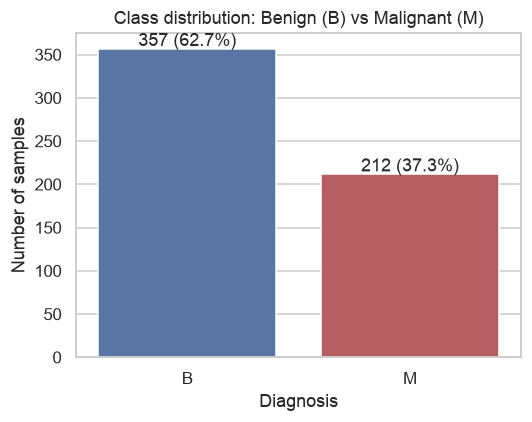

In [5]:

def plot_class_balance(dframe: pd.DataFrame, out_path: str):
    '''Bar plot of the diagnosis class distribution.'''
    fig, ax = plt.subplots(figsize=(5, 4))
    counts = dframe["diagnosis"].value_counts()
    sns.barplot(x=counts.index, y=counts.values, hue=counts.index,
                palette=["#4C72B0", "#C44E52"], legend=False, ax=ax)
    for i, v in enumerate(counts.values):
        ax.text(i, v + 3, f"{v} ({100*v/len(dframe):.1f}%)", ha="center")
    ax.set_xlabel("Diagnosis")
    ax.set_ylabel("Number of samples")
    ax.set_title("Class distribution: Benign (B) vs Malignant (M)")
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()


plot_class_balance(df, os.path.join(FIGURES_DIR, "01_class_balance.png"))


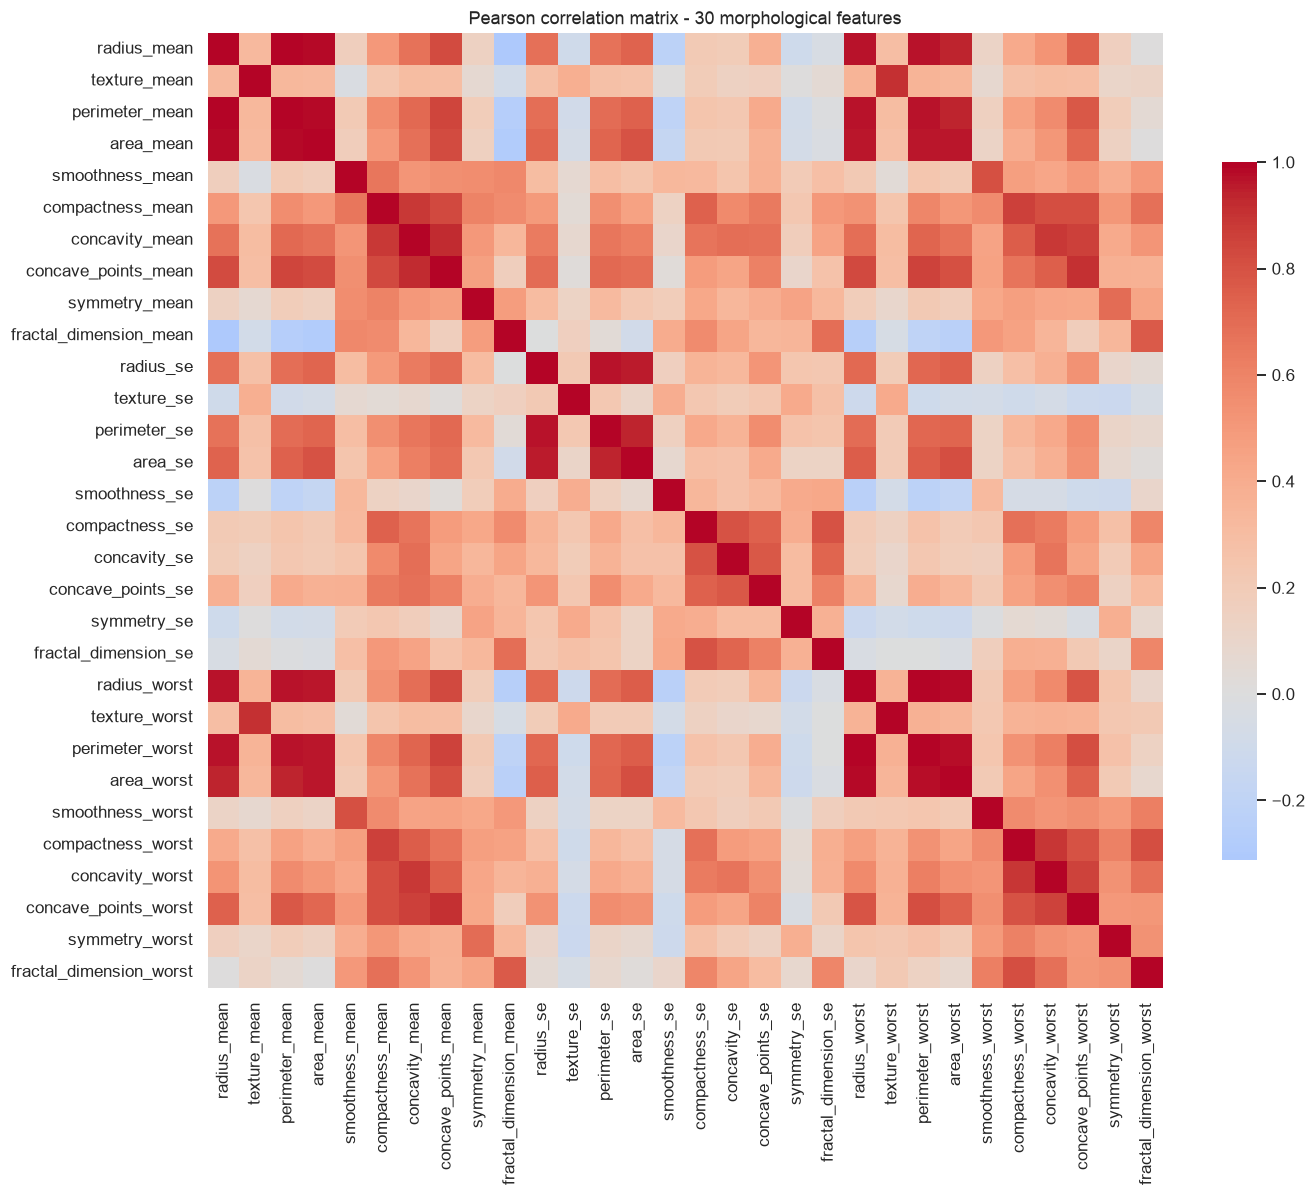

Feature pairs with |correlation| > 0.95 (15 pairs found):

  radius_mean                  <-> perimeter_mean                r = 0.998
  radius_worst                 <-> perimeter_worst               r = 0.994
  radius_mean                  <-> area_mean                     r = 0.987
  perimeter_mean               <-> area_mean                     r = 0.987
  radius_worst                 <-> area_worst                    r = 0.984
  perimeter_worst              <-> area_worst                    r = 0.978
  radius_se                    <-> perimeter_se                  r = 0.973
  perimeter_mean               <-> perimeter_worst               r = 0.970
  radius_mean                  <-> radius_worst                  r = 0.970
  perimeter_mean               <-> radius_worst                  r = 0.969


In [6]:

def plot_correlation_heatmap(dframe: pd.DataFrame, feature_list: list, out_path: str):
    '''Heatmap of the Pearson correlation matrix across all features.'''
    corr = dframe[feature_list].corr()
    fig, ax = plt.subplots(figsize=(13, 11))
    sns.heatmap(corr, cmap="coolwarm", center=0, square=True,
                cbar_kws={"shrink": 0.7}, ax=ax)
    ax.set_title("Pearson correlation matrix - 30 morphological features")
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()


def get_top_correlated_pairs(dframe: pd.DataFrame, feature_list: list,
                              threshold: float = 0.95) -> list:
    '''Return feature pairs with |Pearson correlation| above the given threshold,
    sorted by decreasing correlation.'''
    corr = dframe[feature_list].corr().abs()
    pairs = []
    for i in range(len(feature_list)):
        for j in range(i + 1, len(feature_list)):
            if corr.iloc[i, j] > threshold:
                pairs.append((feature_list[i], feature_list[j], corr.iloc[i, j]))
    return sorted(pairs, key=lambda x: -x[2])


plot_correlation_heatmap(df, features, os.path.join(FIGURES_DIR, "02_correlation_heatmap.png"))

top_pairs = get_top_correlated_pairs(df, features, threshold=0.95)
pd.DataFrame(top_pairs, columns=["feature_1", "feature_2", "pearson_r"]).to_csv(
    os.path.join(TABLES_DIR, "01_correlated_feature_pairs.csv"), index=False)
print(f"Feature pairs with |correlation| > 0.95 ({len(top_pairs)} pairs found):\n")
for f1, f2, corr_val in top_pairs[:10]:
    print(f"  {f1:28s} <-> {f2:28s}  r = {corr_val:.3f}")



**Interpretation.** As expected from the geometry of the measurements, `radius`,
`perimeter`, and `area` (in their mean/worst versions) are almost perfectly correlated
(r > 0.97). This confirms the redundancy flagged in the literature and has two direct
consequences for later steps: 
- (i) tree-based feature importance or univariate filters
may arbitrarily favor one of these redundant features over the others, and 
- (ii) dimensionality reduction (PCA) or regularized models (Lasso/Elastic Net) will be
particularly relevant in Milestone 2 to handle this redundancy properly.


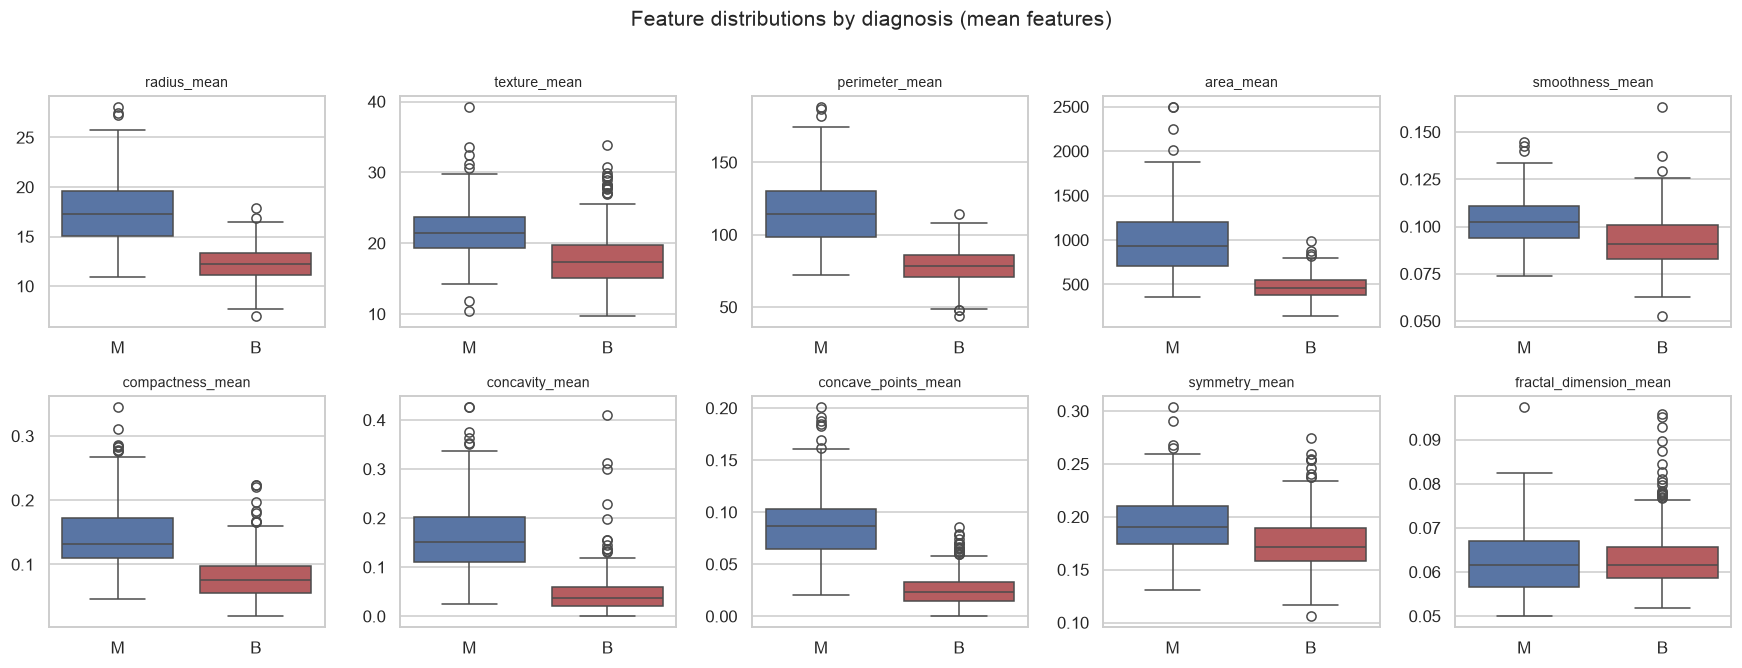

In [7]:

def plot_boxplots_by_diagnosis(dframe: pd.DataFrame, feature_list: list, out_path: str,
                                n_cols: int = 5):
    '''Grid of boxplots comparing each feature's distribution across diagnosis groups.'''
    n_feat = len(feature_list)
    n_rows = int(np.ceil(n_feat / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 3 * n_rows))
    axes = axes.flatten()
    for i, f in enumerate(feature_list):
        sns.boxplot(data=dframe, x="diagnosis", y=f, hue="diagnosis",
                    palette=["#4C72B0", "#C44E52"], legend=False, ax=axes[i])
        axes[i].set_title(f, fontsize=9)
        axes[i].set_xlabel("")
        axes[i].set_ylabel("")
    for j in range(i + 1, len(axes)):
        axes[j].axis("off")
    fig.suptitle("Feature distributions by diagnosis (mean features)", y=1.01, fontsize=14)
    fig.tight_layout()
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.show()


mean_features = [f for f in features if f.endswith("_mean")]
plot_boxplots_by_diagnosis(df, mean_features, os.path.join(FIGURES_DIR, "03_boxplots_mean_features.png"))



**Interpretation.** 
- Malignant samples show visibly higher `radius_mean`, `perimeter_mean`,
`area_mean`, `concavity_mean`, and `concave_points_mean` than benign ones, with limited
overlap for some features — a strong signal that a supervised classifier should be able to
exploit. 
- `symmetry_mean` and `fractal_dimension_mean` show more overlap between classes,
suggesting they carry comparatively less discriminative power on their own.


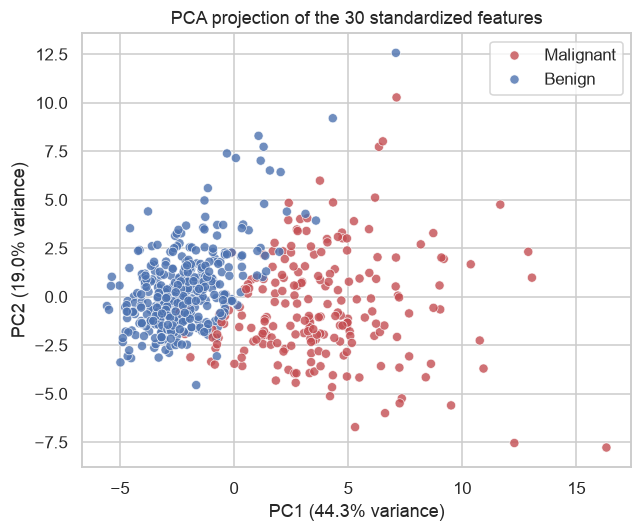

PC1 + PC2 explain 63.2% of total variance



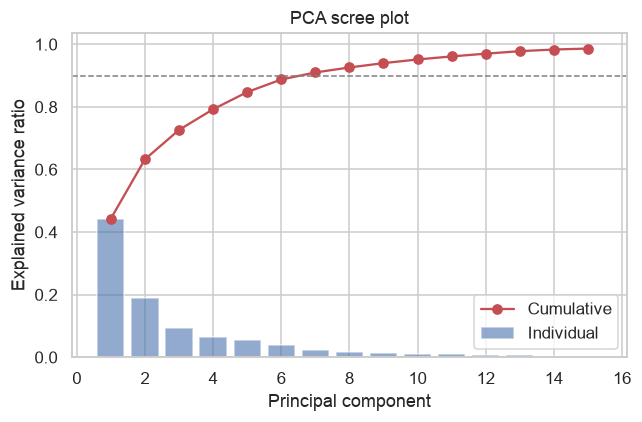

7 principal components are needed to reach 90% cumulative variance


In [8]:

def plot_pca_projection(X_scaled: np.ndarray, y: np.ndarray, out_path: str):
    '''2D PCA projection of the standardized data, colored by diagnosis.'''
    pca_local = PCA(n_components=2, random_state=RANDOM_STATE)
    X_pca_local = pca_local.fit_transform(X_scaled)
    var_explained = pca_local.explained_variance_ratio_

    fig, ax = plt.subplots(figsize=(6, 5))
    labels = np.where(y == 1, "Malignant", "Benign")
    sns.scatterplot(x=X_pca_local[:, 0], y=X_pca_local[:, 1], hue=labels,
                     palette={"Benign": "#4C72B0", "Malignant": "#C44E52"},
                     alpha=0.8, ax=ax)
    ax.set_xlabel(f"PC1 ({var_explained[0]*100:.1f}% variance)")
    ax.set_ylabel(f"PC2 ({var_explained[1]*100:.1f}% variance)")
    ax.set_title("PCA projection of the 30 standardized features")
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()
    return pca_local, X_pca_local


def plot_pca_scree(X_scaled: np.ndarray, out_path: str, n_components: int = 15):
    '''Scree plot: individual and cumulative explained variance per component.'''
    pca_local = PCA(n_components=n_components, random_state=RANDOM_STATE)
    pca_local.fit(X_scaled)
    cum_var = np.cumsum(pca_local.explained_variance_ratio_)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(range(1, n_components + 1), pca_local.explained_variance_ratio_,
           alpha=0.6, label="Individual")
    ax.plot(range(1, n_components + 1), cum_var, marker="o", color="#C44E52",
            label="Cumulative")
    ax.axhline(0.9, color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel("Principal component")
    ax.set_ylabel("Explained variance ratio")
    ax.set_title("PCA scree plot")
    ax.legend()
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()
    return cum_var


X_all = df[features].values
y_all = df["label"].values
X_all_scaled = StandardScaler().fit_transform(X_all)

pca, X_pca = plot_pca_projection(X_all_scaled, y_all, os.path.join(FIGURES_DIR, "04_pca_projection.png"))
print(f"PC1 + PC2 explain {sum(pca.explained_variance_ratio_)*100:.1f}% of total variance\n")

cum_var = plot_pca_scree(X_all_scaled, os.path.join(FIGURES_DIR, "05_pca_scree.png"))
n_90 = int((cum_var < 0.90).sum() + 1)
print(f"{n_90} principal components are needed to reach 90% cumulative variance")



**Interpretation.** Even though PC1 and PC2 only capture ~63% of the total variance
(consistent with 30 correlated but not fully redundant features), the 2D PCA projection
already shows a clear — though not perfect — separation between benign and malignant
samples along PC1. 

This is an encouraging sign that : 
- a linear or near-linear supervised model could perform well (tested in Section 5)
- and that unsupervised clustering on the full standardized feature space might partially recover the diagnosis without ever seeing the labels (tested in Section 6). 

Reaching 90% of the variance requires about 7 components, meaning the effective dimensionality of the data is much lower than the raw 30 features — a direct consequence of the redundancy identified in the correlation heatmap.


## 4. Preprocessing

Before fitting any model, we prepare the data in two steps: 
- **(a)** split it into a training set and a test set, then 
- **(b)** standardize the features. Both steps matter for how fairly the models will be evaluated later.

### 4.1 Why split the data at all?

A model's training error tells us how well it memorized the patients it already saw, not
how it would perform on a *new* patient. Holding out a **test set** that no model ever
sees during training or model selection is the only way to get an honest estimate of
real-world performance. The test set here is only touched once, at the very end (Section
5's ROC curves / confusion matrices) — model selection itself happens by cross-validation
on the training set only (see Section 5).

### 4.2 `train_test_split(...)`: what each argument does

```python
train_test_split(X, y, test_size=test_size, random_state=random_state, stratify=y)
```

- **`X`**: the explanatory variables — here, the matrix of the 30 morphological features
  (one row per patient).
- **`y`**: the target variable to predict — `label` (1 = malignant, 0 = benign).
- **`test_size=0.3`**: fraction of samples set aside for testing (30% here, i.e. ~171 of
  the 569 patients; the remaining 70%, ~398, go to training). 
- **`random_state=42`**: fixes *which* patients end up in train vs. test, so the split is
  identical every time this notebook is rerun (same seed used everywhere, Section 1).
- **`stratify=y`**: forces the train set and the test set to keep the same
  malignant/benign proportion as the full dataset. Without it, a random split could — by
  bad luck — under- or over-represent malignant cases in the test set, biasing every
  evaluation metric computed on it.

### 4.3 Standardization: what and why

`StandardScaler` rescales each feature to zero mean and unit variance:
`x' = (x - mean) / std`, so no feature dominates just because of its raw units
(e.g. `area_mean` ~ hundreds vs. `smoothness_mean` ~ 0.1, Section 2).

Not every method used in this notebook actually needs it:

| Method | Needs scaling? | Why |
|---|---|---|
| K-Means | Yes | Clusters by Euclidean distance |
| K-Nearest Neighbors | Yes | Classifies by distance to neighbors |
| SVM (all kernels) | Yes | Margin/kernel computations are distance-based similarities |
| Logistic Regression | Yes | Gradient descent + regularization penalize large-scale features unfairly |
| LDA / QDA | Yes | Covariance estimates are skewed by feature scale |
| PCA | Yes | Directions of max variance are skewed by scale |
| Decision Tree | No | Splits on one feature's threshold at a time, scale-invariant |
| Random Forest | No | Splits on one feature's threshold at a time, scale-invariant |
| AdaBoost | No | Same reason as Random Forest (built from shallow trees) |

Crucially, the scaler is **fit on the training set only**, then only *applied* (never
re-fit) to the test set — fitting it on the full dataset would leak test-set information
into training, artificially inflating the apparent performance (**data leakage**).


In [9]:

def split_and_scale(dframe: pd.DataFrame, feature_list: list, test_size: float = 0.3,
                     random_state: int = RANDOM_STATE):
    '''Stratified train/test split followed by standardization (fit on train only).

    Returns X_train, X_test, y_train, y_test, scaler
    '''
    X = dframe[feature_list].values
    y = dframe["label"].values

    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=test_size, random_state=random_state, stratify=y)

    scaler_local = StandardScaler()
    X_tr_scaled = scaler_local.fit_transform(X_tr)
    X_te_scaled = scaler_local.transform(X_te)

    return X_tr_scaled, X_te_scaled, y_tr, y_te, scaler_local


X_train, X_test, y_train, y_test, scaler = split_and_scale(df, features, test_size=0.3)

print(f"Train set: {X_train.shape[0]} samples")
print(f"Test set:  {X_test.shape[0]} samples")
print(f"Train class balance: {np.bincount(y_train)} (benign, malignant)")
print(f"Test class balance:  {np.bincount(y_test)} (benign, malignant)")


Train set: 398 samples
Test set:  171 samples
Train class balance: [250 148] (benign, malignant)
Test class balance:  [107  64] (benign, malignant)


## 5. Baseline supervised methods

To address **Q1**, we test ten standard classifiers covering different modeling
families:
- a linear model (**Logistic Regression**),
- an instance-based method (**K-Nearest Neighbors**),
- a margin-based kernel method, compared across three kernels (**SVM: linear, RBF,
  polynomial**) — motivated by Section 3's PCA plot, which suggested a boundary close to
  linear, worth testing directly against more flexible kernels rather than assuming RBF
  is best,
- two generative models sharing the same Gaussian assumption but differing in
  flexibility (**LDA**: shared covariance, linear boundary; **QDA**: per-class
  covariance, quadratic boundary),
- a single tree (**Decision Tree**), and the two ensembles built from it: bagging
  (**Random Forest**) and boosting (**AdaBoost**), to measure what ensembling actually
  buys over one tree.

Each is evaluated with **10-fold stratified cross-validation** on the training set,
reporting accuracy, precision, recall, F1-score, and ROC-AUC — the last three being
particularly important given the class imbalance and the clinical cost of missing a
malignant case (false negative).


### 5.1 Models compared

We compare ten classifiers split into two families, depending on whether they assume a
fixed functional form (**parametric**) or let their complexity grow with the data
(**non-parametric**). Contrasting both is deliberate: it tests whether a flexible,
assumption-free model can beat a simple linear one — the analysis in Section 5.3 shows
whether that flexibility actually pays off here.

#### Parametric models

A parametric model fixes its functional form in advance, described by a fixed, finite
number of parameters that does not change with sample size — more data only makes the
estimate of those same parameters more precise.

| Model | Family | Key idea |
|---|---|---|
| Logistic Regression | Linear | Fits a linear decision boundary; outputs a probability via a sigmoid function |
| SVM (linear) | Margin-based, linear kernel | Finds the hyperplane that maximizes the margin between the two classes |
| LDA | Generative, linear boundary | Assumes both classes share one Gaussian distribution (one covariance matrix for both) |
| QDA | Generative, quadratic boundary | Assumes each class follows its own Gaussian distribution (own covariance matrix) |

#### Non-parametric models

A non-parametric model does not fix its functional form in advance: its effective
complexity (number of neighbors compared, support vectors retained, tree splits made) can
grow with the amount of data. We include them specifically to check whether the true
decision boundary needs more flexibility than a straight line or a quadratic surface — if
none of them clearly beats the parametric models above, that is itself informative about
the data (Section 5.3), not a wasted comparison.

| Model | Family | Key idea |
|---|---|---|
| K-Nearest Neighbors | Instance-based | Classifies a point by majority vote among its `k` closest neighbors (k=5 here) |
| Decision Tree | Tree-based (single tree) | Recursively splits on one feature at a time to build a tree of decision rules |
| SVM (RBF) | Margin-based, non-linear kernel | Maps data to a higher-dimensional space to draw a smooth, curved boundary |
| SVM (poly) | Margin-based, polynomial kernel | Like RBF, but the boundary is built from polynomial combinations of features (degree 3) |
| Random Forest | Ensemble of trees (bagging) | Averages predictions from many decision trees, each trained on a random subset of data/features |
| AdaBoost | Ensemble of trees (boosting) | Fits weak trees sequentially, each one focusing on the previous one's mistakes |


### 5.2 Why look beyond accuracy?

The dataset has **357 benign (62.7%) vs. 212 malignant (37.3%)** patients — not perfectly
balanced. A model that always predicts "benign" would already reach 62.7% accuracy
without learning anything, while missing every single cancer. Accuracy alone does not
say *what kind* of mistake a model makes, hence the additional metrics below, all derived
from the confusion matrix (TP/FP/FN/TN):

| Metric | Question it answers | Formula |
|---|---|---|
| Accuracy | Overall, what fraction of patients is correctly classified? | (TP+TN) / total |
| Precision | Of all patients predicted malignant, how many truly are? | TP / (TP+FP) |
| Recall | Of all truly malignant patients, how many did the model catch? | TP / (TP+FN) |
| F1-score | Single number balancing precision and recall | harmonic mean(precision, recall) |
| ROC-AUC | Does the model separate the two classes well, across *every* decision threshold (not just 0.5)? | area under the ROC curve |

In a cancer diagnosis setting, **recall is the most clinically critical metric**: a false
negative (predicting "benign" for a malignant tumor) means a missed cancer, far more
costly than a false positive (predicting "malignant" for a benign mass, which only leads
to further testing).

Each metric is computed on the **10 cross-validation folds** separately: `_mean` is the
average expected performance, `_std` is how much that performance varies across folds — a
low `_std` means the model behaves consistently regardless of which patients end up in
which fold.


### 5.3 Cross-validated results

We now run all 10 models through the same 10-fold stratified cross-validation and
compare them on the five metrics defined above.


In [10]:
def get_baseline_classifiers(random_state: int = RANDOM_STATE) -> dict:
    '''Return a dictionary of standard baseline classifiers.

    Three SVM kernels are compared (linear, RBF, polynomial) since the PCA projection
    in Section 3 suggested a boundary close to linear, worth checking directly against
    the more flexible RBF and polynomial kernels rather than assuming RBF is best.
    LDA/QDA and AdaBoost are added to cover families not otherwise represented: a
    generative linear model (LDA, shared covariance) paired with its quadratic
    counterpart (QDA, per-class covariance), and sequential boosting. A single Decision
    Tree is added alongside Random Forest and AdaBoost so the benefit of ensembling
    (bagging/boosting) over one interpretable tree can be measured directly.
    '''
    return {
        "Logistic Regression": LogisticRegression(max_iter=5000, random_state=random_state),
        "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
        "SVM (linear)": SVC(kernel="linear", probability=True, random_state=random_state),
        "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=random_state),
        "SVM (poly)": SVC(kernel="poly", degree=3, probability=True, random_state=random_state),
        "Decision Tree": DecisionTreeClassifier(random_state=random_state),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=random_state),
        "LDA": LinearDiscriminantAnalysis(),
        "QDA": QuadraticDiscriminantAnalysis(reg_param=0.1),  # unregularized QDA fails:
        # covariance matrix of the benign class is not full rank (Section 3's
        # correlation heatmap shows several |r| > 0.95 feature pairs)
        "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=random_state),
    }


def cross_validate_classifiers(classifiers: dict, X: np.ndarray, y: np.ndarray,
                                cv_folds: int = 10, random_state: int = RANDOM_STATE) -> pd.DataFrame:
    '''Run stratified k-fold cross-validation for each classifier and summarize results.'''
    cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=random_state)
    scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

    rows = []
    for name, clf in classifiers.items():
        scores = cross_validate(clf, X, y, cv=cv, scoring=scoring)
        row = {"model": name}
        for metric in scoring:
            row[f"{metric}_mean"] = scores[f"test_{metric}"].mean()
            row[f"{metric}_std"] = scores[f"test_{metric}"].std()
        rows.append(row)
    return pd.DataFrame(rows).sort_values("roc_auc_mean", ascending=False)


classifiers = get_baseline_classifiers()
cv_results = cross_validate_classifiers(classifiers, X_train, y_train, cv_folds=10)
cv_results.round(4).to_csv(os.path.join(TABLES_DIR, "02_supervised_cv_results.csv"), index=False)
cv_results[["model", "accuracy_mean", "precision_mean", "recall_mean",
            "f1_mean", "roc_auc_mean"]].round(4)


,model,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean
8,AdaBoost,0.9674,0.9808,0.9324,0.9543,0.9943
4,SVM (poly),0.8946,1.0000,0.7167,0.8284,0.9930
3,SVM (RBF),0.9749,0.9800,0.9529,0.9655,0.9927
0,Logistic Regression,0.9773,0.9866,0.9524,0.9684,0.9926
6,LDA,0.9523,0.9929,0.8786,0.9297,0.9922
2,SVM (linear),0.9598,0.9666,0.9257,0.9434,0.9918
7,QDA,0.9697,0.9795,0.9386,0.9573,0.9885
5,Random Forest,0.9473,0.9362,0.9257,0.9286,0.9845
1,K-Nearest Neighbors,0.9573,0.9857,0.8986,0.9387,0.9841


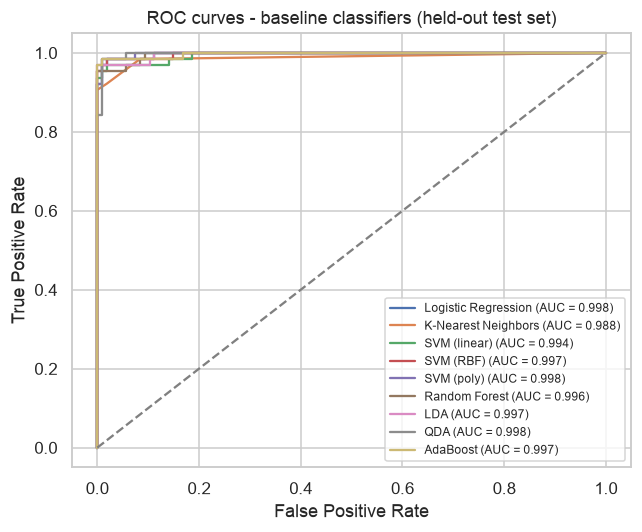

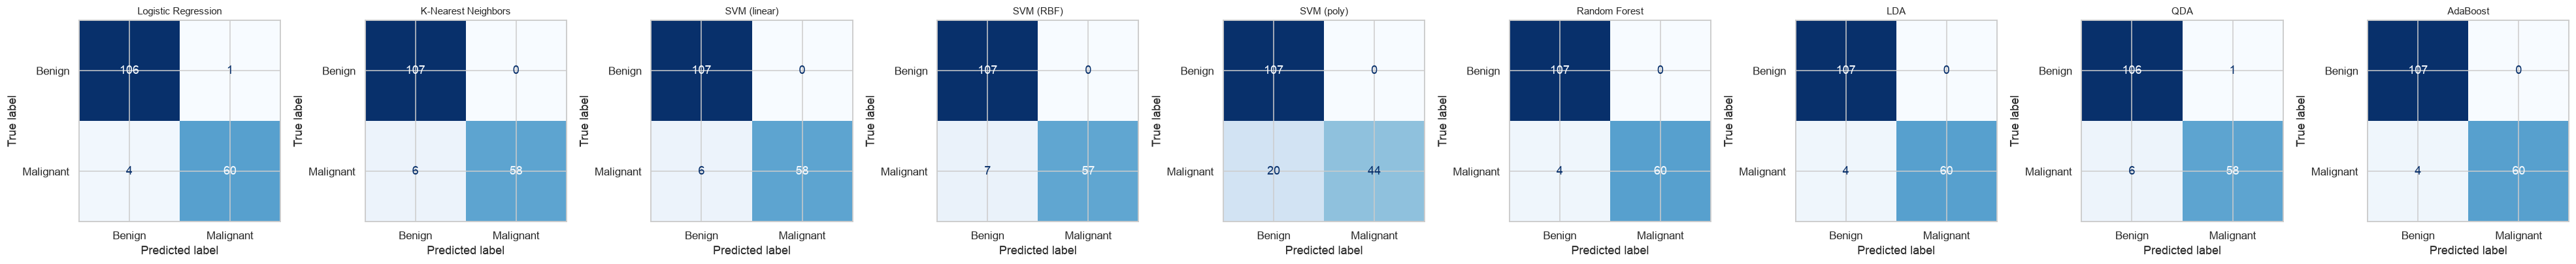

In [11]:

def plot_roc_curves(classifiers: dict, X_tr, y_tr, X_te, y_te, out_path: str):
    '''Fit each classifier on the train set and plot ROC curves on the held-out test set.'''
    fig, ax = plt.subplots(figsize=(6, 5))
    for name, clf in classifiers.items():
        clf.fit(X_tr, y_tr)
        y_score = clf.predict_proba(X_te)[:, 1]
        fpr, tpr, _ = roc_curve(y_te, y_score)
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title("ROC curves - baseline classifiers (held-out test set)")
    ax.legend(loc="lower right", fontsize=8)
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()


def plot_confusion_matrices(classifiers: dict, X_tr, y_tr, X_te, y_te, out_path: str):
    '''Plot a grid of confusion matrices, one per fitted classifier, on the test set.'''
    n = len(classifiers)
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    for ax, (name, clf) in zip(axes, classifiers.items()):
        clf.fit(X_tr, y_tr)
        y_pred = clf.predict(X_te)
        cm = confusion_matrix(y_te, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                       display_labels=["Benign", "Malignant"])
        disp.plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(name, fontsize=10)
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()


plot_roc_curves(get_baseline_classifiers(), X_train, y_train, X_test, y_test,
                os.path.join(FIGURES_DIR, "06_roc_curves.png"))
plot_confusion_matrices(get_baseline_classifiers(), X_train, y_train, X_test, y_test,
                         os.path.join(FIGURES_DIR, "07_confusion_matrices.png"))


**Visualizing the Decision Tree.** Since interpretability is exactly what the tree-based comparison above is about, it is worth actually looking at the tree structure rather than only citing its scores. The full tree used in Section 5.3's cross-validation has no depth limit and would be unreadably large to display, so the plot below fits a separate, depth-limited copy (`max_depth=3`) on the training set purely for this visualization — its scores are not the ones reported above.


In [ ]:

def plot_decision_tree_structure(X_tr, y_tr, feature_list: list, out_path: str, max_depth: int = 3):
    '''Fit a depth-limited Decision Tree on the train set and plot its structure.

    Limited to max_depth=3 purely for readability: the unrestricted tree scored in
    Section 5.3's cross-validation has no depth limit and is too large to display
    legibly. This illustrates the model's interpretability, not its cross-validated
    performance.
    '''
    tree_clf = DecisionTreeClassifier(max_depth=max_depth, random_state=RANDOM_STATE)
    tree_clf.fit(X_tr, y_tr)
    fig, ax = plt.subplots(figsize=(16, 8))
    plot_tree(tree_clf, feature_names=feature_list, class_names=["Benign", "Malignant"],
              filled=True, rounded=True, fontsize=8, ax=ax)
    ax.set_title(f"Decision Tree structure (max_depth={max_depth}, for readability only)")
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()


plot_decision_tree_structure(X_train, y_train, features,
                              os.path.join(FIGURES_DIR, "11_decision_tree.png"))


**Interpretation.** Nine of the ten baselines score well above a trivial classifier; the
tenth, the standalone **Decision Tree**, is a deliberate exception (see below).

- **Logistic Regression** and **SVM (RBF)** remain the two strongest models overall on
  the metric that matters most clinically (recall), both catching ~95% of malignant
  cases with very high precision.

- **AdaBoost** achieves the single best ROC-AUC (0.994) of all ten models, but its
  recall (93.2%) is a bit below the top two — another reminder that AUC alone does not
  pick the best model for this task (see Section 5.2).

- **LDA vs. QDA** is the most instructive parametric comparison: despite sharing the
  same Gaussian assumption, **LDA's recall (87.9%) is the worst among the well-behaved
  models** — worse even than KNN — while **QDA reaches 93.9%**. Letting each class have
  its own covariance (QDA) clearly captures something LDA's shared covariance cannot
  here. Note also that LDA ran with no numerical issues, while unregularized QDA failed
  outright ("covariance matrix is not full rank"): pooling both classes into one shared
  covariance estimate (LDA) uses more effective samples per parameter than estimating
  two separate ones (QDA), which is why only QDA needed regularization (`reg_param=0.1`)
  against the strong feature collinearity from Section 3.

- **SVM (polynomial)** is still the clearest metric-mismatch example: *highest* ROC-AUC
  among the SVMs (0.993) but by far the *lowest* recall of the well-behaved models
  (71.7%) — it misses more than a quarter of the real cancers despite looking excellent
  on a threshold-independent metric.

- **Decision Tree vs. its own ensembles** is the clearest illustration of *why* ensemble
  methods exist. The single tree reaches only **ROC-AUC = 0.911** (accuracy 91.5%, F1
  0.885) — dramatically below every other model — and its **std (0.050 on ROC-AUC) is
  2 to 5x higher** than any other model's, meaning its performance swings wildly
  depending on which patients land in which fold: a textbook symptom of a
  high-variance, overfitting-prone model. **Random Forest**, an average over many such
  trees (bagging), lifts ROC-AUC to 0.985 — a **+0.074 gain purely from ensembling**,
  with a much lower std (0.019). **AdaBoost**, which instead re-weights and chains
  shallow trees (boosting), does even better (ROC-AUC 0.994). The trade-off is
  interpretability: a single Decision Tree can be read and explained node by node,
  while Random Forest and AdaBoost cannot (Figure 11 shows a depth-limited copy of the tree for exactly this reason) — directly illustrating the CM4
  interpretability-vs-performance tension from lecture.

- **Random Forest** and **K-Nearest Neighbors** trail the top group, most likely because
  Random Forest is less sample-efficient with 30 correlated features and ~400 training
  samples than a regularized linear model, and KNN's fixed neighborhood (k=5) is more
  sensitive to local density variations near the class boundary.

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| **Logistic Regression** | 0.977 | 0.987 | 0.952 | **0.968** | 0.993 |
| **SVM (RBF)** | 0.975 | 0.980 | **0.953** | 0.966 | 0.993 |
| QDA | 0.970 | 0.980 | 0.939 | 0.957 | 0.989 |
| AdaBoost | 0.967 | 0.981 | 0.932 | 0.954 | **0.994** |
| SVM (linear) | 0.960 | 0.967 | 0.926 | 0.943 | 0.992 |
| K-Nearest Neighbors | 0.957 | 0.986 | 0.899 | 0.939 | 0.984 |
| LDA | 0.952 | **0.993** | 0.879 | 0.930 | 0.992 |
| Random Forest | 0.947 | 0.936 | 0.926 | 0.929 | 0.985 |
| SVM (polynomial) | 0.895 | **1.000** | 0.717 | 0.828 | 0.993 |
| Decision Tree | 0.915 | 0.881 | 0.898 | 0.885 | 0.911 |

*(10-fold cross-validated means on the training set; bold marks the best value per column.)*

This is a first, simple illustration of the "optimal approach" trade-off the project asks us to justify in Milestone 2: 
- a simple linear model (or an RBF kernel close to linear behavior here) already performs excellently, 
- but we still need to test more advanced or combined strategies before concluding it is the best choice.


## 6. Baseline unsupervised methods

To address **Q2**, we investigate whether the data naturally separate into groups
**without using the diagnosis labels**, then measure — only for evaluation purposes —
how well the discovered structure agrees with the true diagnosis. All external metrics
below use the diagnosis only for evaluation, never for fitting the clustering algorithms
themselves.


### 6.1 Finding the optimal number of clusters

Before comparing clustering algorithms, we first check how many clusters the data
actually support, using two complementary methods:

- **Elbow method**: plots **inertia** (sum of squared distances from each point to its
  cluster's center — a measure of cluster compactness) against `k`. Inertia always
  decreases as `k` grows, so we don't minimize it directly; instead we look for the
  "elbow" — the point past which adding more clusters stops buying a meaningful drop.

- **Silhouette score**: for each point, compares its distance to its own cluster against its distance to the nearest other cluster, into a score between -1 and 1 (higher = better-separated clusters). Unlike inertia it does not automatically favor more clusters, so — unlike inertia — it can be compared directly across `k` values.

They are complementary: the elbow gives a quick visual cue, the silhouette gives a
comparable numeric score across `k` — using both makes the choice of `k` more robust than
either alone.


### 6.2 Clustering methods compared

| Method | Family | Key idea |
|---|---|---|
| K-Means | Centroid-based | Assigns each point to the nearest of `k` centroids, then updates centroids iteratively |
| Agglomerative (ward) | Hierarchical | Merges the two clusters whose fusion increases within-cluster variance the least |
| Agglomerative (average) | Hierarchical | Merges the two clusters with the smallest *average* pairwise distance between their points |
| Agglomerative (complete) | Hierarchical | Merges the two clusters with the smallest *maximum* pairwise distance between their points |
| Spectral | Graph-based | Builds a similarity graph between points, then clusters based on its structure — can capture non-convex shapes the others can't |
| DBSCAN | Density-based | Groups points in dense regions together, marks isolated points as noise |


### 6.3 Clustering evaluation metrics

| Metric | Type | Question it answers |
|---|---|---|
| Silhouette score | Internal (label-free) | Are points closer to their own cluster than to the next-closest one? |
| Homogeneity | External | Does each cluster contain only members of a single true class? |
| Completeness | External | Are all members of a true class placed in the same cluster? |
| V-measure | External | Single number balancing homogeneity and completeness |
| ARI | External | Overall agreement with the true diagnosis, corrected for chance |


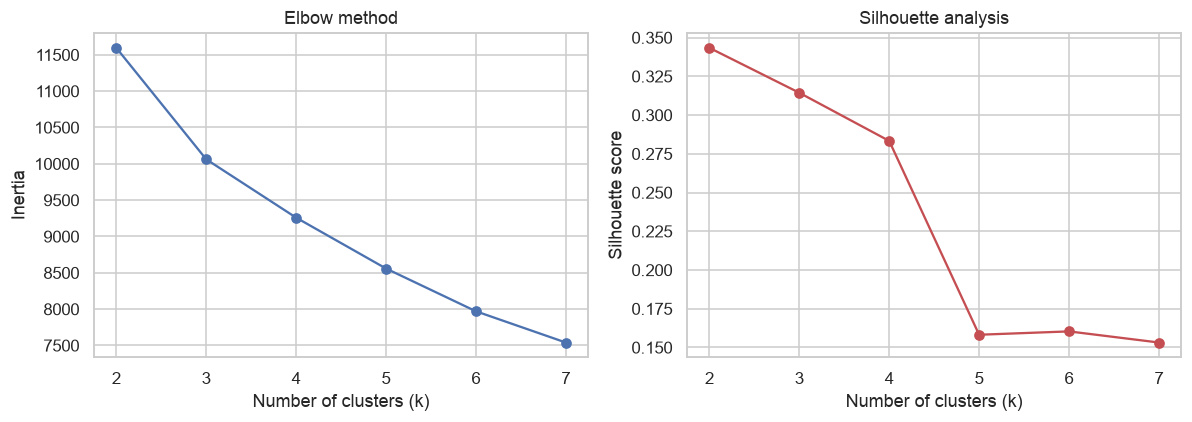

,k,inertia,silhouette
0,2,11595.5266,0.3434
1,3,10061.7978,0.3144
2,4,9258.9891,0.2833
3,5,8558.6607,0.1582
4,6,7970.2638,0.1604
5,7,7540.3187,0.1532


In [12]:
# Choosing optimal k: elbow and silhouette analysis 

def run_kmeans_range(X: np.ndarray, k_range=range(2, 8), random_state: int = RANDOM_STATE) -> pd.DataFrame:
    '''Run K-Means for a range of k values and report inertia and silhouette score.'''
    rows = []
    for k in k_range:
        km = KMeans(n_clusters=k, n_init=10, random_state=random_state)
        labels = km.fit_predict(X)
        sil = silhouette_score(X, labels)
        rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
    return pd.DataFrame(rows)


def plot_elbow_and_silhouette(kmeans_results: pd.DataFrame, out_path: str):
    '''Side-by-side elbow (inertia) and silhouette score plots across k.'''
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(kmeans_results["k"], kmeans_results["inertia"], marker="o")
    axes[0].set_xlabel("Number of clusters (k)")
    axes[0].set_ylabel("Inertia")
    axes[0].set_title("Elbow method")

    axes[1].plot(kmeans_results["k"], kmeans_results["silhouette"], marker="o", color="#C44E52")
    axes[1].set_xlabel("Number of clusters (k)")
    axes[1].set_ylabel("Silhouette score")
    axes[1].set_title("Silhouette analysis")
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()


kmeans_results = run_kmeans_range(X_all_scaled, k_range=range(2, 8))
plot_elbow_and_silhouette(kmeans_results, os.path.join(FIGURES_DIR, "08_elbow_silhouette.png"))
kmeans_results.round(4).to_csv(os.path.join(TABLES_DIR, "03_kmeans_elbow_silhouette.csv"), index=False)
kmeans_results.round(4)



**Interpretation.** Both the elbow curve and the silhouette score point to **k = 2** as the
most natural number of clusters (silhouette drops from 0.343 at k=2 to 0.314 at k=3 and
keeps decreasing), which is a first, encouraging sign that the data's intrinsic structure
is compatible with the binary benign/malignant distinction.


In [13]:
# Comparing clustering methods

def get_baseline_clusterers(random_state: int = RANDOM_STATE) -> dict:
    '''Return standard clustering algorithms configured to look for 2 clusters.

    All three linkage criteria are compared for Agglomerative clustering (Ward,
    average, complete), since the linkage rule changes what "distance between
    clusters" means and can noticeably change the resulting partition. Spectral
    clustering is added as a graph-based alternative that can capture non-convex
    cluster shapes that K-Means/Ward cannot.
    '''
    return {
        "K-Means": KMeans(n_clusters=2, n_init=10, random_state=random_state),
        "Agglomerative (ward)": AgglomerativeClustering(n_clusters=2, linkage="ward"),
        "Agglomerative (average)": AgglomerativeClustering(n_clusters=2, linkage="average"),
        "Agglomerative (complete)": AgglomerativeClustering(n_clusters=2, linkage="complete"),
        "Spectral": SpectralClustering(n_clusters=2, random_state=random_state,
                                        affinity="nearest_neighbors"),
        "DBSCAN": DBSCAN(eps=2.5, min_samples=10),
    }


def evaluate_clusterers(clusterers: dict, X: np.ndarray, y_true: np.ndarray) -> pd.DataFrame:
    '''Evaluate clustering algorithms against the true diagnosis labels.

    Silhouette score is label-free (internal); homogeneity, completeness,
    V-measure, and ARI use the diagnosis only for external validation, never for
    fitting the clustering algorithm.
    '''
    rows = []
    for name, algo in clusterers.items():
        labels = algo.fit_predict(X)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        sil = silhouette_score(X, labels) if n_clusters > 1 else np.nan
        homogeneity = homogeneity_score(y_true, labels)
        completeness = completeness_score(y_true, labels)
        v_measure = v_measure_score(y_true, labels)
        ari = adjusted_rand_score(y_true, labels)
        rows.append({"model": name, "n_clusters_found": n_clusters,
                      "silhouette": sil, "homogeneity": homogeneity,
                      "completeness": completeness, "v_measure": v_measure,
                      "ARI_vs_diagnosis": ari})
    return pd.DataFrame(rows)


clusterers = get_baseline_clusterers()
cluster_eval = evaluate_clusterers(clusterers, X_all_scaled, y_all)
cluster_eval.round(4).to_csv(os.path.join(TABLES_DIR, "04_clustering_eval.csv"), index=False)
cluster_eval.round(4)


,model,n_clusters_found,silhouette,homogeneity,completeness,v_measure,ARI_vs_diagnosis
0,K-Means,2,0.3434,0.5249,0.5401,0.5324,0.6536
1,Agglomerative (ward),2,0.3394,0.4462,0.4681,0.4569,0.5750
2,Agglomerative (average),2,0.6340,0.0079,0.1589,0.0151,0.0073
3,Agglomerative (complete),2,0.6607,0.0053,0.1489,0.0102,0.0048
4,Spectral,2,0.3367,0.6497,0.6762,0.6627,0.7608
5,DBSCAN,2,0.0307,0.2584,0.2117,0.2327,0.2649


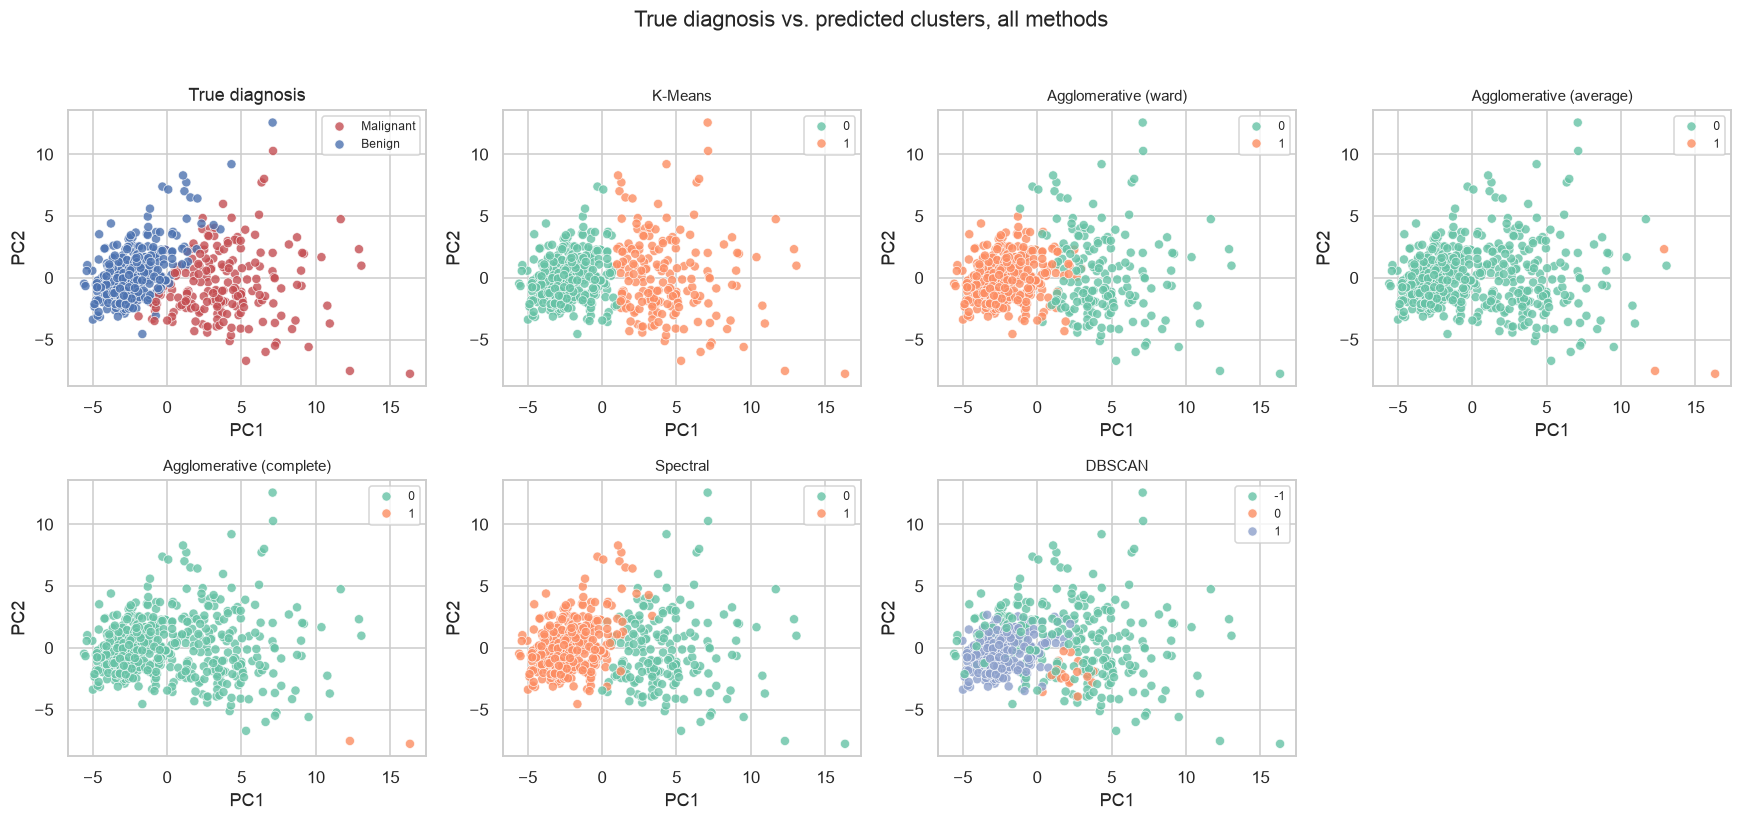

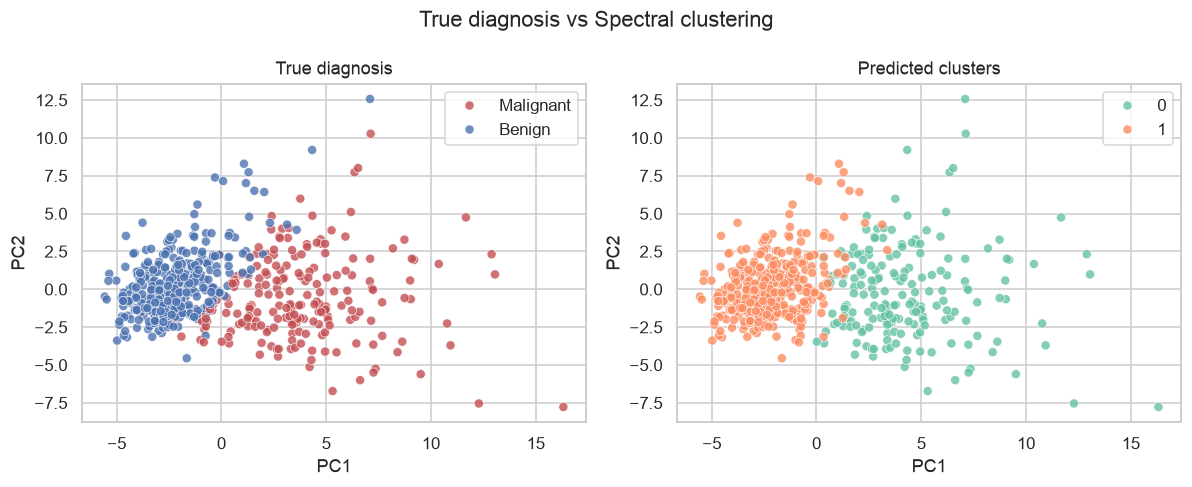

In [14]:

def plot_cluster_vs_diagnosis(X_pca_2d: np.ndarray, y_true: np.ndarray, cluster_labels: np.ndarray,
                               out_path: str, title: str = "Predicted clusters vs true diagnosis"):
    '''Side-by-side PCA scatter comparing true diagnosis and predicted clusters.'''
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    diag_labels = np.where(y_true == 1, "Malignant", "Benign")
    sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=diag_labels,
                     palette={"Benign": "#4C72B0", "Malignant": "#C44E52"},
                     alpha=0.8, ax=axes[0])
    axes[0].set_title("True diagnosis")
    axes[0].set_xlabel("PC1")
    axes[0].set_ylabel("PC2")

    sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=cluster_labels,
                     palette="Set2", alpha=0.8, ax=axes[1])
    axes[1].set_title("Predicted clusters")
    axes[1].set_xlabel("PC1")
    axes[1].set_ylabel("PC2")

    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()


def plot_all_clusters_vs_diagnosis(X_pca_2d: np.ndarray, y_true: np.ndarray,
                                    cluster_labels_dict: dict, out_path: str,
                                    n_cols: int = 4):
    '''Grid comparing the true diagnosis to every clustering method's partition.'''
    diag_labels = np.where(y_true == 1, "Malignant", "Benign")
    n_panels = 1 + len(cluster_labels_dict)
    n_rows = int(np.ceil(n_panels / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.8 * n_rows))
    axes = axes.flatten()

    sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=diag_labels,
                     palette={"Benign": "#4C72B0", "Malignant": "#C44E52"},
                     alpha=0.8, ax=axes[0])
    axes[0].set_title("True diagnosis")
    axes[0].legend(fontsize=8, loc="best", title=None)

    # Cluster label numbers (0, 1, ...) are arbitrary integers assigned by each
    # algorithm -- they carry no fixed correspondence to malignant/benign, and the
    # same number can mean a different group from one algorithm to the next. Each
    # panel gets its own legend so the color <-> number mapping is at least
    # unambiguous *within* that panel.
    for i, (name, labels) in enumerate(cluster_labels_dict.items(), start=1):
        sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=labels,
                         palette="Set2", alpha=0.8, ax=axes[i])
        axes[i].set_title(name, fontsize=10)
        axes[i].legend(fontsize=8, loc="best", title=None)

    for ax in axes[:n_panels]:
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
    for j in range(n_panels, len(axes)):
        axes[j].axis("off")

    fig.suptitle("True diagnosis vs. predicted clusters, all methods")
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(out_path, dpi=150)
    plt.show()



cluster_labels_all = {name: algo.labels_ for name, algo in clusterers.items()}
plot_all_clusters_vs_diagnosis(X_pca, y_all, cluster_labels_all,
                                os.path.join(FIGURES_DIR, "09_all_clusters_vs_diagnosis.png"))

# Highlight figure: Spectral clustering specifically, since it achieves the best
# agreement with the true diagnosis (Section 6.5's results table).
spectral_labels = clusterers["Spectral"].labels_
plot_cluster_vs_diagnosis(X_pca, y_all, spectral_labels,
                           os.path.join(FIGURES_DIR, "10_spectral_vs_diagnosis.png"),
                           title="True diagnosis vs Spectral clustering")


**Interpretation.** The six clustering methods tell a much richer story than a single
metric would suggest.

- **Spectral clustering achieves the best agreement with the true diagnosis** (ARI =
  0.761, V-measure = 0.663), ahead of **K-Means** (ARI = 0.654) and **Agglomerative
  (ward)** (ARI = 0.575) — its graph-based similarity apparently captures the
  benign/malignant structure slightly better than distance-to-centroid (K-Means) or
  variance-minimizing (Ward) approaches.

- **Agglomerative (average)** and **Agglomerative (complete)** are a cautionary tale, not a genuine result: they report the *highest* silhouette scores of all six methods (0.634 and 0.661) while their ARI is essentially **zero** (0.007 and 0.005). Checking the actual cluster sizes explains why: average linkage returns a 566/3 split and complete linkage a 567/2 split — nearly every point in one cluster, plus 2-3 outliers isolated into their own "cluster". A silhouette score cannot tell this apart from a real partition: one giant, self-similar blob plus a trivially well-separated singleton looks "cohesive" by construction. This is the clustering equivalent of the SVM (polynomial) situation in Section 5: a single aggregate metric, taken alone, can rank the *worst* result as the *best*.

- **DBSCAN** again performs poorly (ARI = 0.265). Its legend shows three label values
  (-1, 0, 1), but **-1 is not a cluster** — it is DBSCAN's label for points it could not assign to any sufficiently dense region ("noise"). Concretely: cluster 0 holds 17
  points, cluster 1 holds 288 points, and **264 points (46% of the dataset) are marked as noise**. DBSCAN genuinely finds only 2 clusters here, but fails to place nearly half the data into either one — consistent with Section 3's earlier finding (the PCA projection) that the two classes
  partially overlap in feature space, which a density-based method struggles with.

| Model | Silhouette | Homogeneity | Completeness | V-measure | ARI |
|---|---|---|---|---|---|
| **Spectral** | 0.337 | 0.650 | 0.676 | **0.663** | **0.761** |
| K-Means | 0.343 | 0.525 | 0.540 | 0.532 | 0.654 |
| Agglomerative (ward) | 0.339 | 0.446 | 0.468 | 0.457 | 0.575 |
| DBSCAN | 0.031 | 0.258 | 0.212 | 0.233 | 0.265 |
| Agglomerative (average) | **0.634** | 0.008 | 0.159 | 0.015 | 0.007 |
| Agglomerative (complete) | **0.661** | 0.005 | 0.149 | 0.010 | 0.005 |

*(bold marks the best value per column — note how the "best" silhouette rows are the*
*worst on every external metric.)*

The two PCA figures below make this concrete. 
- The **grid of all six methods** shows the average/complete degeneracy visually: their panels are one uniform blob of color with a couple of stray points, unlike K-Means, Ward, and Spectral, whose panels show a real two-region split resembling the true diagnosis panel. 

- The second figure, **True diagnosis vs. Spectral clustering** (the best performer above), confirms this: 
  - its predicted partition closely mirrors the true diagnosis, with most disagreements concentrated near the boundary between the two point clouds — exactly where borderline biological cases would be expected. 
  
  - This is a strong, label-free confirmation that the benign/malignant distinction is not just a clinical label but a real, geometrically coherent structure in the feature space — which directly answers **Q2** at this baseline stage, while also illustrating why external validation (ARI/V-measure) must accompany any internal metric (silhouette) before trusting a clustering result.


## 7. Synthesis and next steps

**Summary of Milestone 1 findings**

- The dataset is clean (no missing values, no duplicates) with a moderate class imbalance (63% benign / 37% malignant), which we accounted for using stratified splits and AUC/precision/recall metrics.

- Strong redundancy exists among geometrically related features (`radius`, `perimeter`,
  `area`): 15 feature pairs have |Pearson r| > 0.95 — an important consideration for
  feature selection in Milestone 2, and the direct cause of QDA's numerical failure
  without regularization (Section 5).

- A 2D PCA projection already separates the two diagnosis classes reasonably well
  (63.2% variance explained by PC1+PC2), and ~7 components are enough to capture 90% of
  the total variance, indicating a much lower effective dimensionality than the raw 30
  features.

- **Supervised baselines** (10 models, 10-fold CV): nine perform strongly (ROC-AUC
  between 0.984 and 0.994).
  - **Logistic Regression** and **SVM (RBF)** are the best all-round
  choices (recall ~95%, F1 ~0.97); **AdaBoost** reaches the single highest AUC (0.994) but with lower recall;
  - **SVM (polynomial)** and **LDA** are cautionary examples of models
 that look strong on precision/AUC while missing a large share of malignant cases
  (recall 71.7% and 87.9% respectively) — a reminder that no single metric should decide the "best" model;
  - the tenth, a standalone **Decision Tree**, is the deliberate exception: ROC-AUC only
  0.911 with 2-5x higher fold-to-fold variance than any other model, versus 0.985 for
  **Random Forest** (bagging) and 0.994 for **AdaBoost** (boosting) built from the same
  kind of tree — a direct, quantified demonstration of why ensembling helps.

- **Unsupervised baselines** (6 methods) show that: 
  - **Spectral clustering** best recovers the true diagnosis from the feature geometry alone (ARI = 0.761), ahead of **K-Means** (ARI = 0.654), directly supporting Q2.
  - Agglomerative **average/complete** linkage are a methodological pitfall: both report the *highest* silhouette scores while finding a degenerate near-single-cluster partition (ARI ≈ 0), 
  - and **DBSCAN** classifies 46% of points as noise.

**What Milestone 2 will build on this**

- Deepen the **feature selection** analysis (Q3): compare filter (correlation, mutual
  information), embedded (Lasso, Random Forest importance), and wrapper (RFE) methods to
  identify a compact, non-redundant, and biologically interpretable set of discriminative
  variables — directly addressing the collinearity that already caused issues for QDA
  here.
- Now that **Spectral clustering** already outperforms K-Means/Ward on the raw feature
  space, check whether clustering on the **PCA-reduced** space (the ~7 components needed
  for 90% variance) changes this ranking, and whether the average/complete linkage
  failure persists after dimensionality reduction or was specific to the raw 30-feature
  space.
- Push the **supervised** comparison further with hyperparameter tuning and, potentially,
  an interpretable model such as a cascade classifier with abstention (as illustrated on
  this exact dataset in Clertant et al., 2019, AISTATS), to justify a final "optimal"
  approach with respect to accuracy, simplicity, and clinical interpretability.


In [15]:
best_by_f1 = cv_results.sort_values("f1_mean", ascending=False).iloc[0]
best_by_auc = cv_results.sort_values("roc_auc_mean", ascending=False).iloc[0]
best_cluster_by_ari = cluster_eval.sort_values("ARI_vs_diagnosis", ascending=False).iloc[0]

# "Overall" best = lowest average rank across all 5 metrics at once, rather than
# picking a single metric -- consistent with Section 5.2's point that no one metric
# should decide a "best" model.
_metrics = ["accuracy_mean", "precision_mean", "recall_mean", "f1_mean", "roc_auc_mean"]
_avg_rank = cv_results.set_index("model")[_metrics].rank(ascending=False).mean(axis=1).sort_values()
best_overall_name, runner_up_name = _avg_rank.index[0], _avg_rank.index[1]
best_overall_row = cv_results.set_index("model").loc[best_overall_name]
runner_up_row = cv_results.set_index("model").loc[runner_up_name]

run_summary = {
    "run_info": {
        "random_state": RANDOM_STATE,
        "n_samples": int(df.shape[0]),
        "n_features": len(features),
        "train_size": int(X_train.shape[0]),
        "test_size": int(X_test.shape[0]),
    },
    "output_files": {
        # Paths are relative to the project root (05_figures/, 04_results/tables/),
        # listed straight from disk so this summary can never drift out of sync
        # with what was actually saved.
        "figures": [os.path.join("05_figures", f) for f in sorted(os.listdir(FIGURES_DIR))],
        "tables": [os.path.join("04_results", "tables", f) for f in sorted(os.listdir(TABLES_DIR))],
    },
    "top_results": {
        "best_supervised_model_overall": {
            "model": best_overall_name,
            "avg_rank_across_5_metrics": round(float(_avg_rank.iloc[0]), 2),
            "f1_mean": round(float(best_overall_row["f1_mean"]), 4),
            "recall_mean": round(float(best_overall_row["recall_mean"]), 4),
            "roc_auc_mean": round(float(best_overall_row["roc_auc_mean"]), 4),
            "runner_up": {
                "model": runner_up_name,
                "avg_rank_across_5_metrics": round(float(_avg_rank.iloc[1]), 2),
                "f1_mean": round(float(runner_up_row["f1_mean"]), 4),
                "recall_mean": round(float(runner_up_row["recall_mean"]), 4),
                "roc_auc_mean": round(float(runner_up_row["roc_auc_mean"]), 4),
            },
        },
        "best_supervised_model_by_f1": {
            "model": best_by_f1["model"],
            "f1_mean": round(float(best_by_f1["f1_mean"]), 4),
            "recall_mean": round(float(best_by_f1["recall_mean"]), 4),
            "roc_auc_mean": round(float(best_by_f1["roc_auc_mean"]), 4),
        },
        "best_supervised_model_by_roc_auc": {
            "model": best_by_auc["model"],
            "roc_auc_mean": round(float(best_by_auc["roc_auc_mean"]), 4),
            "recall_mean": round(float(best_by_auc["recall_mean"]), 4),
        },
        "best_clustering_method_by_ari": {
            "model": best_cluster_by_ari["model"],
            "ARI_vs_diagnosis": round(float(best_cluster_by_ari["ARI_vs_diagnosis"]), 4),
            "silhouette": round(float(best_cluster_by_ari["silhouette"]), 4),
        },
    },
}

summary_path = os.path.join(RESULTS_DIR, "run_summary.json")
with open(summary_path, "w") as f:
    json.dump(run_summary, f, indent=2)

print(f"Run summary written to {summary_path}")
run_summary


Run summary written to ../03_results/run_summary.json


{'run_info': {'random_state': 42,
  'n_samples': 569,
  'n_features': 30,
  'train_size': 398,
  'test_size': 171},
 'output_files': {'figures': ['figures/01_class_balance.png',
   'figures/02_correlation_heatmap.png',
   'figures/03_boxplots_mean_features.png',
   'figures/04_pca_projection.png',
   'figures/05_pca_scree.png',
   'figures/06_roc_curves.png',
   'figures/07_confusion_matrices.png',
   'figures/08_elbow_silhouette.png',
   'figures/09_all_clusters_vs_diagnosis.png',
   'figures/10_spectral_vs_diagnosis.png'],
  'tables': ['tables/00_outlier_report.csv',
   'tables/01_correlated_feature_pairs.csv',
   'tables/02_supervised_cv_results.csv',
   'tables/03_kmeans_elbow_silhouette.csv',
   'tables/04_clustering_eval.csv']},
 'top_results': {'best_supervised_model_overall': {'model': 'Logistic Regression',
   'avg_rank_across_5_metrics': 2.2,
   'f1_mean': 0.9684,
   'recall_mean': 0.9524,
   'roc_auc_mean': 0.9926,
   'runner_up': {'model': 'SVM (RBF)',
    'avg_rank_across_